# Modèle épidémiologique

Les modèles compartimentaux sont traditionnellement utilisés dans la modélisation de phénomène épidémiologiques. Ce sont des modèles mathématiques fondés sur des équations différentielles stochastiques décrivant les interactions entre différents compartiments de la population et dont on cherche à estimer les paramètres. Comme pour les modèles VAR, on réalise une estimation par pays.

L'inconvénient majeur est que ce type de méthodes requiert une expertise et n'est pas directement applicable sur des données brutes comme l'apprentissage de dictionnaire.

Repartons du modèle SIR (Suspected-Infected-Recovered), proposé par F. Bauer dans *Mathematical epidemiology* (2008), à la section 2.1.3 "Kermack–McKendrick Models with General Contact Rates", pages 32–34.

**Principe :**

On répartit la population en quatre compartiments :

- $S(t)$ : individus susceptibles d'être infectés ;
- $I(t)$ : individus infectieux ;
- $R(t)$ : individus guéris ;
- $D(t)$ : individus décédés.

Les transitions entre ces compartiments sont gouvernées par trois paramètres :

- $\beta$ : taux de transmission ;
- $\alpha$ : taux de sortie du compartiment infectieux ;
- $f$ : proportion des sorties correspondant à une guérison, avec $1-f$ pour les décès.

**Formalisation du modèle :**

Nous considérons une population initiale $N_0$ et supposons une incidence standard, proportionnelle à $SI/N_0$.

Le modèle SIRD s'écrit :

$$
\begin{cases}
\displaystyle \frac{dS}{dt}=-\beta\frac{SI}{N_0},\\[6pt]
\displaystyle \frac{dI}{dt}=\beta\frac{SI}{N_0}-\alpha I,\\[6pt]
\displaystyle \frac{dR}{dt}=f\alpha I,\\[6pt]
\displaystyle \frac{dD}{dt}=(1-f)\alpha I.
\end{cases}
$$

Ce système constitue une adaptation du modèle de Brauer distinguant guérisons et décès.

**Adaptation aux données disponibles :**

Pour chaque pays, nous disposons de trois séries temporelles cumulées :

- $C(t)$ : cas confirmés cumulés (*confirmed*) ;
- $R(t)$ : guérisons cumulées (*recovered*) ;
- $D(t)$ : décès cumulés (*deaths*).

Nous supposons que les cas confirmés se répartissent entre individus encore infectés, guéris et décédés :

$$
I(t)=C(t)-R(t)-D(t).
$$

En supposant une population fermée et l'absence de réinfection (plausible à moyen terme) :

$$
S(t)+I(t)+R(t)+D(t)=N_0.
$$

Ainsi :

$$
S(t)=N_0-C(t).
$$

Nous pouvons donc éliminer les compartiments $S$ et $I$ du système, et obtenir un modèle exprimé uniquement à partir des trois variables observées :

$$
\boxed{
\begin{cases}
\displaystyle \frac{dC}{dt}=\beta\left(1-\frac{C}{N_0}\right)(C-R-D),\\[8pt]
\displaystyle \frac{dR}{dt}=f\alpha(C-R-D),\\[8pt]
\displaystyle \frac{dD}{dt}=(1-f)\alpha(C-R-D).
\end{cases}
}
$$

Le modèle dépend donc de trois paramètres à estimer :

$$
\theta=(\beta,\alpha,f),
\qquad
\beta\geq 0,\quad \alpha\geq 0,\quad f\in[0,1].
$$

Nous fixons $N_0$ à la population nationale en 2020.

**Estimation des paramètres :**

Pour chaque pays, nous estimons les paramètres $\theta$ à partir des données d'entraînement, jusqu'au 12 avril 2020.

Pour une valeur donnée de $\theta$, nous résolvons numériquement le système d'équations différentielles afin d'obtenir les trajectoires prédites :

$$
\widehat C_\theta(t),\qquad
\widehat R_\theta(t),\qquad
\widehat D_\theta(t).
$$

Nous recherchons les paramètres minimisant l'écart entre ces trajectoires et les observations :

$$
\widehat\theta
=
\underset{\theta}{\arg\min}
\sum_{t\in\mathcal T_{\mathrm{train}}}
\sum_{k\in\{C,R,D\}}
w_k\left(X_k(t)-\widehat X_{k,\theta}(t)\right)^2.
$$

Les poids $w_k$ permettent d'éviter qu'une variable présentant des valeurs beaucoup plus élevées domine entièrement l'estimation.

Packages utilisés : `scipy.optimize.least_squares` et `scipy.integrate.solve_ivp`

**Prévision et évaluation :**

Une fois les paramètres estimés, nous prolongeons les trajectoires du modèle sur les **30 jours suivant la période d'entraînement**, du 13 avril au 12 mai 2020.

Les prévisions des nouveaux cas confirmés, nouvelles guérisons et nouveaux décès sont obtenues par différence des trajectoires cumulées :

$$
\begin{aligned}
\widehat c_t&=\widehat C(t)-\widehat C(t-1),\\
\widehat r_t&=\widehat R(t)-\widehat R(t-1),\\
\widehat d_t&=\widehat D(t)-\widehat D(t-1).
\end{aligned}
$$

Nous évaluons les prévisions à l'aide de la RMSE, séparément pour chaque pays et chaque variable, afin de les comparer aux modèles statistiques et à l'Online NMF.

**Limites attendues :**

Le modèle suppose des paramètres $\beta$, $\alpha$ et $f$ constants dans le temps. Or, les interventions sanitaires et les changements de comportement peuvent modifier fortement les dynamiques de transmission.

En particulier, un modèle SIRD à paramètres constants risque de mal anticiper le retournement d'une vague épidémique sur un horizon de 30 jours. Cette limite fait partie de l'intérêt du benchmark. Pour y remédier dans un second temps, on envisagera d'estimer des paramètres qui évoluent avec le temps.

### Préparation des données

In [1]:
# Lecture des données
import pandas as pd

confirmed_path = "../COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"
deaths_path = "../COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_deaths_global.csv"
recovered_path = "../COVID-19/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_recovered_global.csv"

In [2]:
countries = ['Korea, South', 'China', 'US', 'Italy', 'Germany', 'Spain']
cutoff_date = "4/12/20" # Paper's dates: from Jan 19, 2020 to Apr. 12, 2020 -> missing Jan 19, 20, 21
val_date = "5/12/20" # 30 days after cutoff_date, to assess prediction accuracy

In [3]:
def reindex_data(df):
    df = df.T
    df.index.name = "date"
    df.index = pd.to_datetime(df.index, format="%m/%d/%y")
    return df

def preprocess_data(data_path: str, countries: list = countries, cutoff_date: str = cutoff_date):
    df = pd.read_csv(data_path)
    
    cols = list(df.columns)
    df = df[df["Country/Region"].isin(countries)].copy()
    df = df[[col for col in cols[:cols.index(cutoff_date)+1]]]
    df = df.drop(columns=["Lat", "Long", "Province/State"])
    df = df.groupby("Country/Region").sum(numeric_only=True)
    
    return reindex_data(df)

def get_validation_data(
        data_path: str,
        countries: list = countries,
        val_date: str = val_date
    ):
    df = pd.read_csv(data_path)
    cols = list(df.columns)

    df = df[df["Country/Region"].isin(countries)].copy()
    df = df[[col for col in cols[:cols.index(val_date)+1]]]
    df = df.drop(columns=["Lat", "Long", "Province/State"])
    df = df.groupby("Country/Region").sum(numeric_only=True)
    df = df.diff(axis=1).clip(lower=0)
    
    return reindex_data(df)

In [4]:
C = preprocess_data(confirmed_path)
R = preprocess_data(recovered_path)
D = preprocess_data(deaths_path)

In [5]:
C_val = get_validation_data(confirmed_path)
R_val = get_validation_data(recovered_path)
D_val = get_validation_data(deaths_path)

val_data = {
    "C": C_val,
    "R": R_val,
    "D": D_val
}

In [6]:
# Populations
table_path = "../COVID-19/csse_covid_19_data/UID_ISO_FIPS_LookUp_Table.csv"
table = pd.read_csv(table_path)
table.head()

populations = {}
for country in countries:
    populations[country] = table.loc[table["Combined_Key"] == country, "Population"].iloc[0]

In [7]:
data = {}
for country in countries:
    data[country] = {}
    data[country]["pop"] = populations[country]
    data[country]["obs"] = pd.DataFrame({
        "C": C[country],
        "R": R[country],
        "D": D[country]
    })

## Modèle à beta constant sur la période

In [8]:
def sird(t, y, beta, alpha, f, pop) -> tuple[float, float, float]:
    C, R, D = y
    I = C - R - D

    dC = beta * (1 - C/pop) * I
    dR = f * alpha * I
    dD = (1 - f) * alpha * I

    return [dC, dR, dD]

In [9]:
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
import numpy as np

def optimize(theta, observed, country, scale):
    beta, alpha, f = theta

    pop = populations[country]
    t = np.arange(len(observed))

    solution = solve_ivp(
        fun=sird,
        t_span=(t[0], t[-1]),
        y0=observed.iloc[0].to_numpy(dtype=float),
        t_eval=t,
        args=(beta, alpha, f, pop)
    )

    if not solution.success:
        return np.full(observed.size, 1e10)

    predicted = solution.y.T

    errors = (predicted - observed.to_numpy()) / scale

    return errors.ravel()

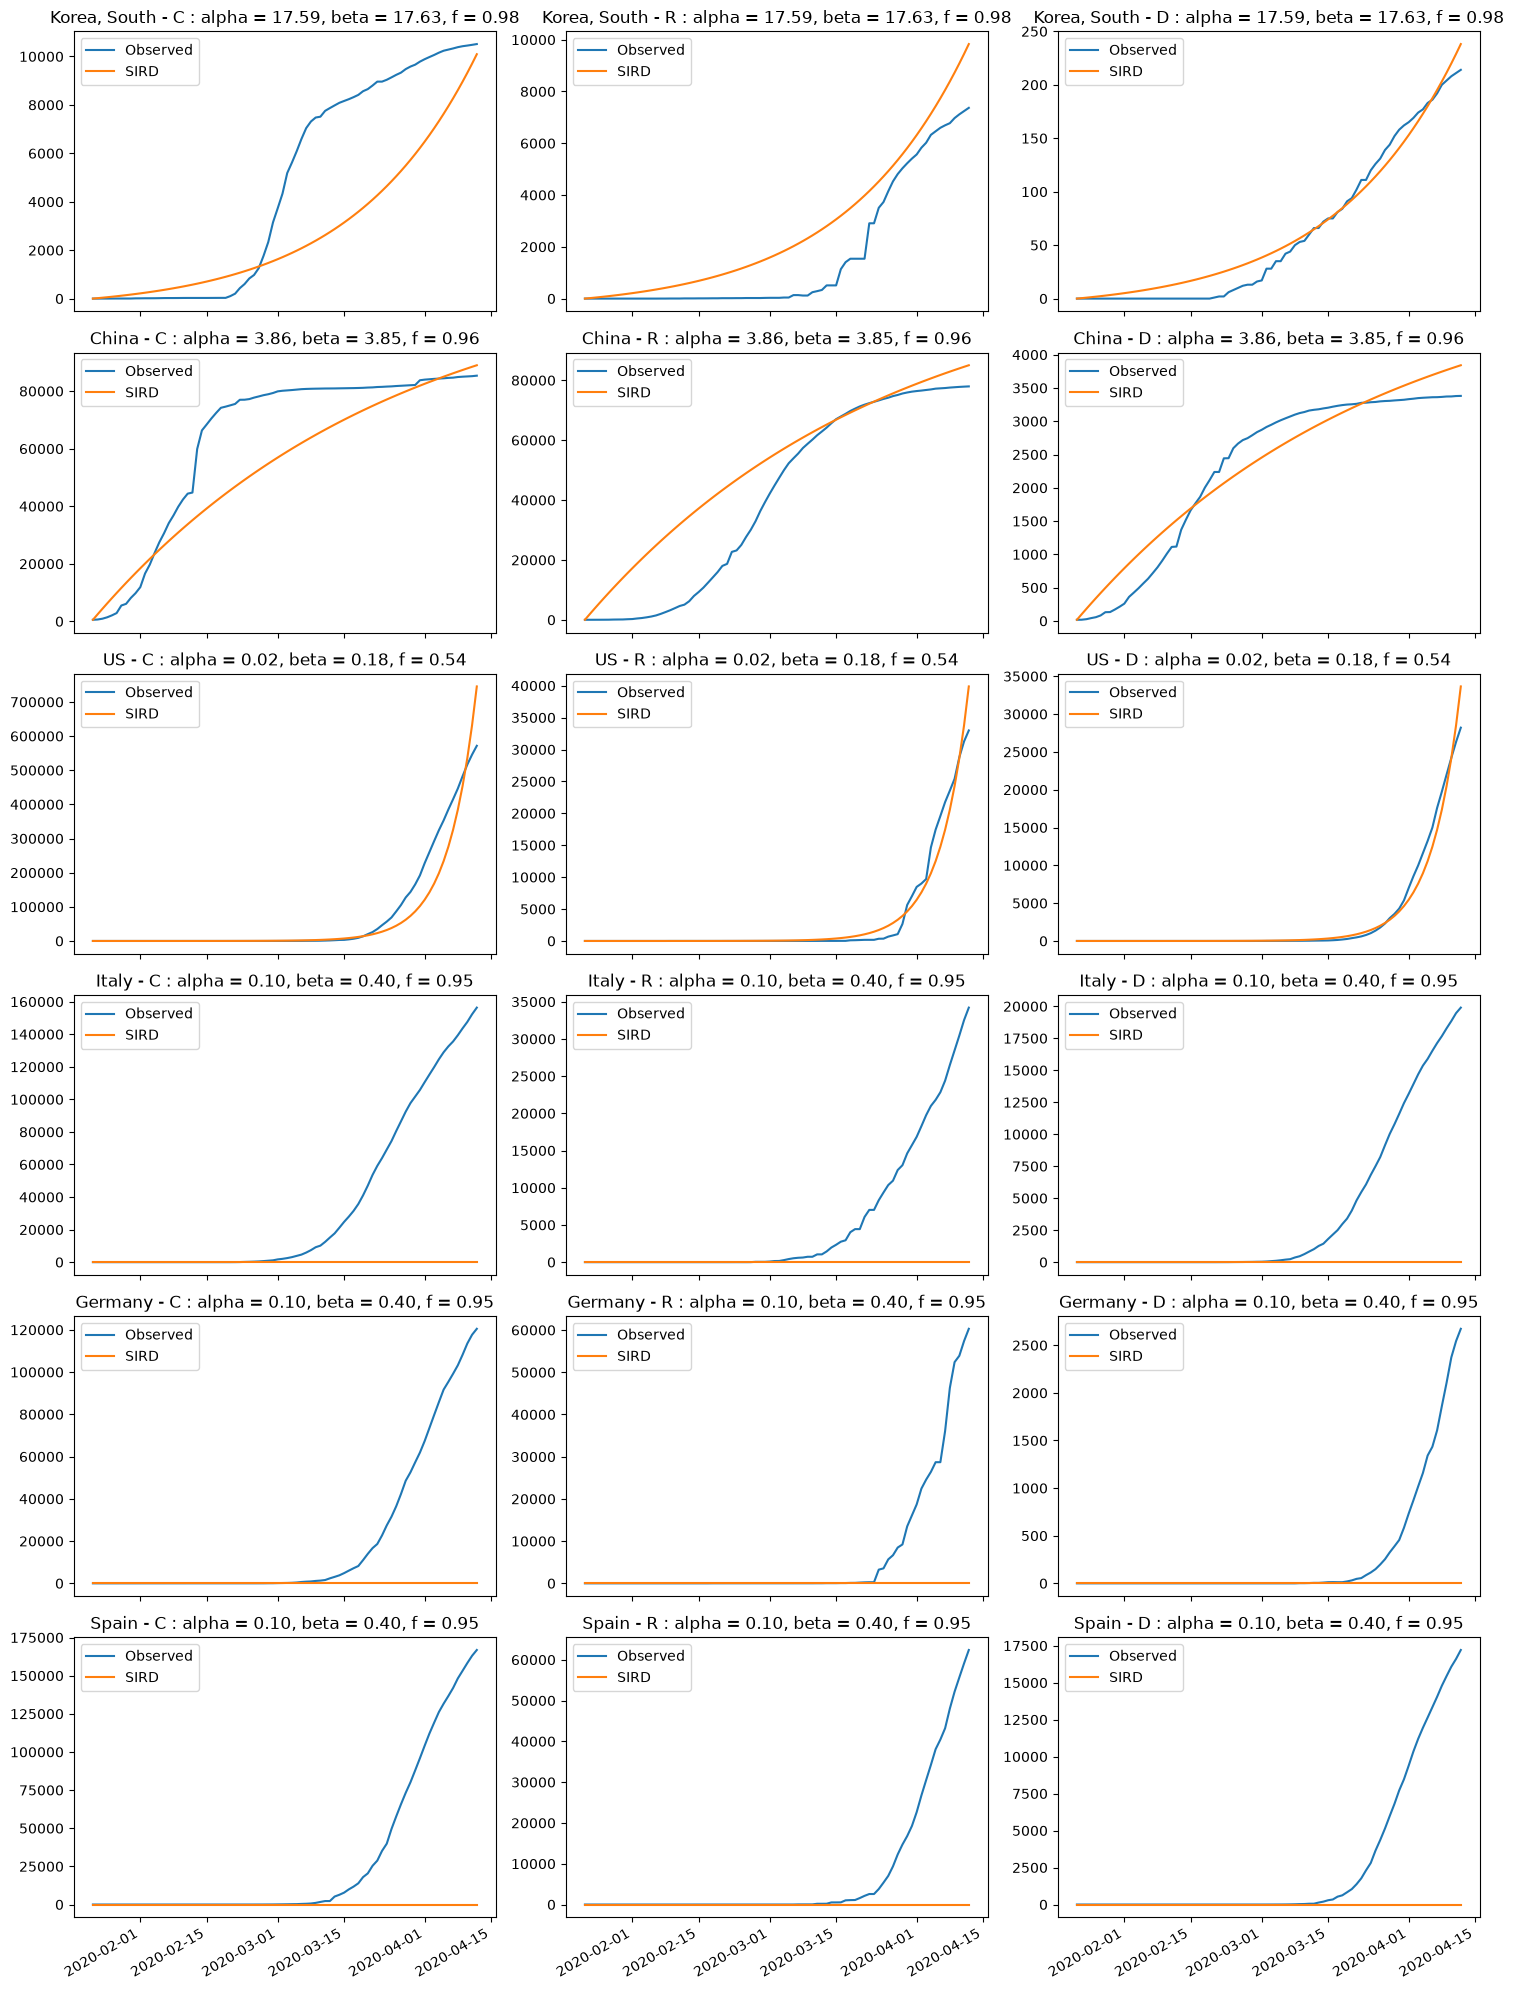

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(6, 3, figsize=(15, 20))

variables = ["C", "R", "D"]

for i, country in enumerate(countries):
    obs = data[country]["obs"]
    t = np.arange(len(obs))
    scale = np.maximum(obs.max().to_numpy(), 1.0)

    for j, variable in enumerate(variables):
        ax = axes[i, j]

        result = least_squares(
            fun=optimize,
            x0=[0.4, 0.1, 0.95],
            args=(obs, country, scale),
            bounds=(
                [0, 0, 0],
                [np.inf, np.inf, 1]
            )
        )
        beta_hat, alpha_hat, f_hat = result.x

        solution = solve_ivp(
            sird, # Fonction qui calcule les dérivées
            t_span=(t[0], t[-1]), # temps
            y0=obs.iloc[0].to_numpy(), # Première observation
            t_eval=t,
            args=(*result.x, populations[country])
        )

        pred = pd.DataFrame(
            solution.y.T,
            index=obs.index,
            columns=obs.columns
        )

        ax.plot(obs.index, obs[variable], label="Observed")
        ax.plot(pred.index, pred[variable], label="SIRD")

        ax.set_title(f"{country} - {variable} : alpha = {alpha_hat:.2f}, beta = {beta_hat:.2f}, f = {f_hat:.2f}")
        ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Modèle à beta constant sur fenêtre glissante
Refaire l'estimation des paramètres sur de plus petites fenêtres -> détecter les changements de dynamiques.

On cherche alors à optimiser :
$$
\boxed{
\widehat\theta_t
=
\underset{\theta}{\arg\min}
\sum_{s=t-w+1}^{t}
\sum_{k\in\{C,R,D\}}
\left(
\frac{\widehat X_{k,\theta}(s)-X_k(s)}{\mathrm{scale}_k}
\right)^2
}
$$

In [11]:
windows = [14, 21, 28, 42]
parameters = {k: [] for k in windows}
country = "Spain"
obs = data[country]["obs"]

for window in windows:
    for end in range(window, len(obs) + 1):

        obs_window = obs.iloc[end-window:end]

        scale = np.maximum(
            obs_window[["C", "R", "D"]].max().to_numpy(),
            1.0
        )

        result = least_squares(
            optimize,
            x0=[0.4, 0.1, 0.95],
            args=(obs_window, country, scale),
            bounds=([0, 0, 0], [np.inf, np.inf, 1])
        )

        parameters[window].append({
            "date": obs_window.index[-1],
            "beta": result.x[0],
            "alpha": result.x[1],
            "f": result.x[2]
        })

    parameters[window] = pd.DataFrame(parameters[window]).set_index("date")

In [18]:
reconstructed = {}

for window in windows:
    reconstructed[window] = obs.copy() * np.nan

    for date, row in parameters[window].iterrows():
        i = obs.index.get_loc(date)

        if i + 1 >= len(obs):
            break

        theta = row[["beta", "alpha", "f"]].to_numpy()

        solution = solve_ivp(
            sird,
            t_span=(0, 1),
            y0=obs.iloc[i].to_numpy(dtype=float),
            t_eval=[1],
            args=(*theta, populations[country])
        )

        if solution.success:
            reconstructed[window].iloc[i + 1] = solution.y[:, -1]

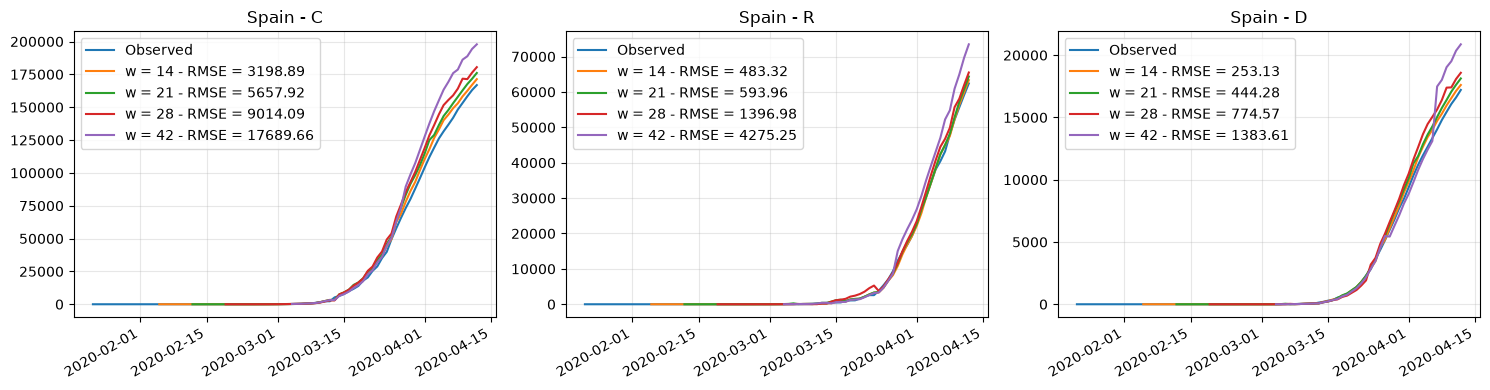

In [19]:
# Plot sur les données cumulées
from sklearn.metrics import root_mean_squared_error

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, variable in zip(axes, variables):
    ax.plot(obs.index, obs[variable], label="Observed")
    
    for window in windows:
        y_pred = reconstructed[window][variable].dropna()
        y_true = obs.loc[y_pred.index, variable]
        rmse = root_mean_squared_error(
            y_true=y_true,
            y_pred=y_pred
        )
        ax.plot(
            reconstructed[window].index,
            reconstructed[window][variable],
            label=f"w = {window} - RMSE = {rmse:.2f}"
        )

        ax.set_title(f"{country} - {variable}")
        ax.legend()
        ax.grid(alpha=0.3)

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

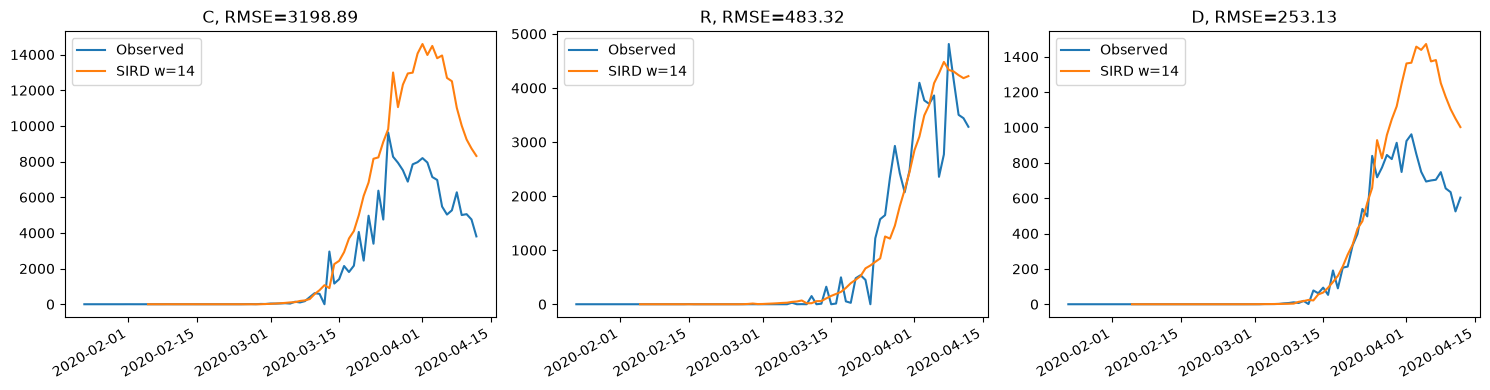

In [37]:
# Plot sur les données quotidiennes
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, variable in zip(axes, variables):
    w = 14
    y_pred = (reconstructed[w][variable] - obs[variable].shift(1)).dropna()
    y_true = obs[variable].diff().loc[y_pred.index]
    rmse = root_mean_squared_error(y_true, y_pred)
    
    ax.plot(obs[variable].diff(), label="Observed")
    ax.plot(y_pred, label=f"SIRD w={w}")

    ax.set_title(f"{variable}, RMSE={rmse:.2f}")
    ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

In [38]:
# Prédicition à un jour
window = 14
country = "Spain"

obs_train = obs.tail(window)

scale = np.maximum(
    obs_train[["C", "R", "D"]].max().to_numpy(),
    1.0
)

# Fit parameters on the last 14 observed days
result = least_squares(
    optimize,
    x0=[0.4, 0.1, 0.95],
    args=(obs_train, country, scale),
    bounds=([0, 0, 0], [np.inf, np.inf, 1])
)

# Forecast one day ahead
solution = solve_ivp(
    sird,
    t_span=(0, 1),
    y0=obs.iloc[-1].to_numpy(dtype=float),
    t_eval=[1],
    args=(*result.x, populations[country])
)

# Cumulative forecast
next_cumulative = solution.y[:, -1]

# Daily forecast
next_daily = next_cumulative - obs.iloc[-1].to_numpy()

print("Estimated parameters (beta, alpha, f):", result.x)
print("Tomorrow's daily forecast:", next_daily)

Estimated parameters (beta, alpha, f): [0.08651206 0.05820247 0.82028808]
Tomorrow's daily forecast: [7625.23094567 4223.4968794   925.30022332]


In [39]:
window = 14
horizon = 30

history = obs.copy()
theta0 = parameters[window].iloc[-1][["beta", "alpha", "f"]].to_numpy()

for h in range(horizon):

    # Fit on the latest window (observed + predicted values)
    obs_train = history.tail(window)
    scale = np.maximum(obs_train.max().to_numpy(), 1.0)

    result = least_squares(
        optimize,
        x0=theta0,
        args=(obs_train, country, scale),
        bounds=([0, 0, 0], [np.inf, np.inf, 1])
    )

    if not result.success:
        raise RuntimeError("SIRD optimization failed")

    theta0 = result.x

    # One-step-ahead prediction
    solution = solve_ivp(
        sird,
        t_span=(0, 1),
        y0=history.iloc[-1].to_numpy(dtype=float),
        t_eval=[1],
        args=(*theta0, populations[country])
    )

    if not solution.success:
        raise RuntimeError("SIRD integration failed")

    next_date = history.index[-1] + pd.Timedelta(days=1)
    history.loc[next_date] = solution.y[:, -1]

# Cumulative forecasts
forecast_cumulative = history.tail(horizon)

# Daily forecasts
forecast_daily = history.diff().tail(horizon)

/var/folders/cb/smr6m6xx6r99ts8034bf09pr0000gn/T/ipykernel_35358/401384382.py:38: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  history.loc[next_date] = solution.y[:, -1]
/var/folders/cb/smr6m6xx6r99ts8034bf09pr0000gn/T/ipykernel_35358/401384382.py:38: Pandas4Warning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. The existing dtype int64 cannot hold the value being set, so the result has dtype float64. Cast the object to float64 before this operation to retain the current behavior.
  history.loc[next_date] = solution.y[:, -1]
/var/folders/cb/smr6m6xx6r99ts8034bf09pr0000gn/T/ipykernel_35358/401384382.py:38: Pandas4Warning: Setting an item of incompatible dtype is deprecated and wi

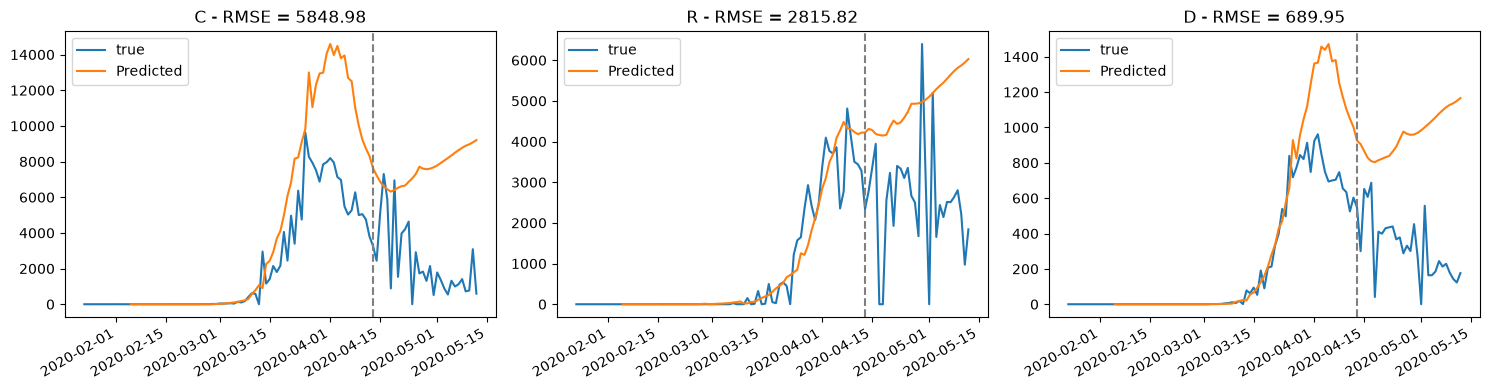

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

for ax, variable in zip(axes, variables):
    val = val_data[variable].copy()

    y_pred = forecast_daily[variable]
    y_true = val.loc[y_pred.index, country]
    rmse = root_mean_squared_error(y_true, y_pred)

    daily_one_step = (reconstructed[window][variable] - obs[variable].shift(1)).dropna()
    predicted = pd.concat([daily_one_step, y_pred])
    
    ax.plot(val[country], label="true")
    ax.plot(predicted, label="Predicted")

    ax.axvline(pd.Timestamp("2020-04-13"), color="grey", linestyle="--")

    ax.set_title(f"{variable} - RMSE = {rmse:.2f}")
    ax.legend()

fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## RMSE calculée sur les 30 jours de prévision !

## Modèle à beta variable

Sur **chaque fenêtre observée**, on ajuste
$\beta(t)=\beta_{\mathrm{fin}}\exp(k(t-t_{\mathrm{fin}}))$,
avec $\theta=(\beta_{\mathrm{fin}},\alpha,f,k)$ et $\alpha,f$ constants dans la fenêtre.
L'objectif reste l'erreur sur les cumulés, normalisée par leur maximum dans la fenêtre.
On initialise l'ajustement par un modèle constant ($k=0$).

Pour l'historique, chaque prévision à un jour repart de la dernière observation de sa fenêtre.
Pour les 30 jours futurs, on conserve les paramètres de la dernière fenêtre **réelle** :
on compare la prolongation exponentielle de β à un β figé à sa valeur finale.
La borne configurable `k_limit = 0.1` (par jour) limite l'extrapolation ; c'est un choix
numérique à évaluer par validation temporelle, pas une constante épidémiologique.
Les fenêtres sans infectés actifs au départ ne permettent pas cet ajustement et sont ignorées.

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares

country_variable = "Spain"
windows_variable = [14, 21, 28, 42]
window_variable = 14  # Fenêtre retenue pour la prévision finale
horizon_variable = 30
k_limit = 0.1
variables_variable = ["C", "R", "D"]
obs_variable = data[country_variable]["obs"][variables_variable].astype(float).copy()
pop_variable = float(populations[country_variable])


def sird_variable(t, y, beta_end, alpha, f, k, pop, t_end):
    C, R, D = y
    I = C - R - D
    beta_t = beta_end * np.exp(k * (t - t_end))
    return [beta_t * (1 - C / pop) * I,
            f * alpha * I, (1 - f) * alpha * I]


def integrate_variable(theta, y0, times, pop, t_end):
    solution = solve_ivp(
        sird_variable, (times[0], times[-1]), y0, t_eval=times,
        args=(*theta, pop, t_end), rtol=1e-7, atol=1e-5,
    )
    if not solution.success or not np.isfinite(solution.y).all():
        raise RuntimeError(f"Échec de l'intégration : {solution.message}")
    return solution.y.T


def residuals_variable(theta, observed, pop):
    times = (observed.index - observed.index[0]).days.to_numpy(dtype=float)
    scale = np.maximum(observed.max().to_numpy(), 1.0)
    try:
        predicted = integrate_variable(
            theta, observed.iloc[0].to_numpy(), times, pop, times[-1]
        )
    except RuntimeError:
        return np.full(observed.size, 1e10)
    return ((predicted - observed.to_numpy()) / scale).ravel()


def fit_variable(observed, pop):
    # Même solveur et même critère pour initialiser avec un β constant.
    constant = least_squares(
        lambda theta: residuals_variable([*theta, 0.0], observed, pop),
        x0=[0.1, 0.05, 0.9],
        bounds=([0, 0, 0], [np.inf, np.inf, 1]), max_nfev=1000,
    )
    if not constant.success:
        raise RuntimeError(f"Initialisation constante : {constant.message}")
    result = least_squares(
        residuals_variable, x0=[*constant.x, 0.0], args=(observed, pop),
        bounds=([0, 0, 0, -k_limit], [np.inf, np.inf, 1, k_limit]),
        max_nfev=1000,
    )
    if not result.success:
        raise RuntimeError(f"Ajustement à β variable : {result.message}")
    return result

w=14 : 49 ajustements, 9 avec k à la borne
w=21 : 42 ajustements, 8 avec k à la borne
w=28 : 35 ajustements, 8 avec k à la borne
w=42 : 21 ajustements, 0 avec k à la borne


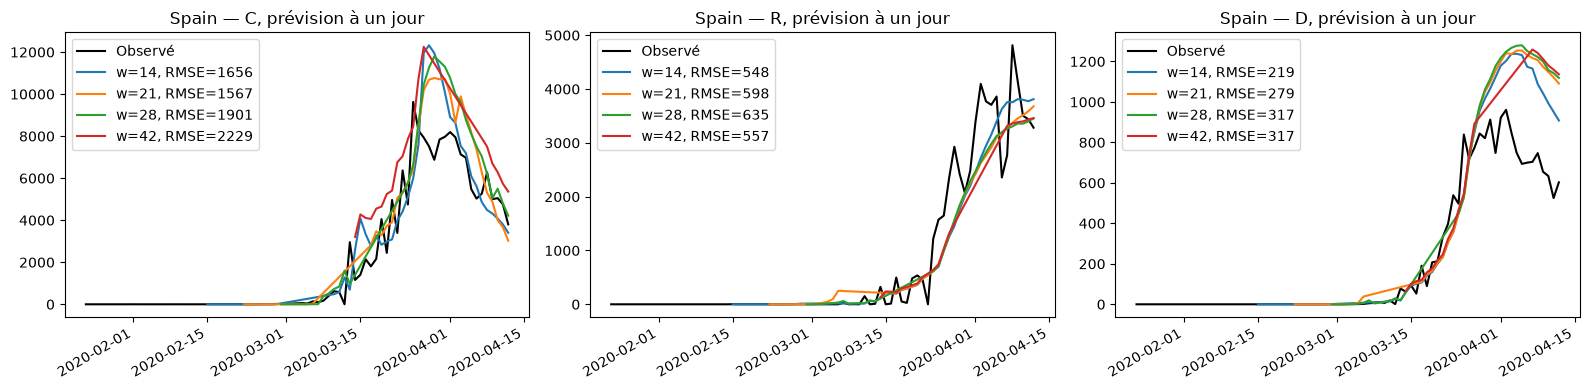

In [43]:
# Ajustement séparé sur chaque fenêtre ; aucune donnée future n'est utilisée.
parameters_variable = {}
reconstructed_variable = {}
for w in windows_variable:
    records = []
    reconstructed_variable[w] = pd.DataFrame(
        np.nan, index=obs_variable.index, columns=variables_variable
    )
    for end in range(w, len(obs_variable) + 1):
        train = obs_variable.iloc[end-w:end]
        initial = train.iloc[0]
        if initial["C"] - initial["R"] - initial["D"] <= 0:
            continue
        result_variable = fit_variable(train, pop_variable)
        beta_end, alpha, f, k = result_variable.x
        records.append({
            "date": train.index[-1], "beta_end": beta_end,
            "alpha": alpha, "f": f, "k": k,
            "cost": result_variable.cost,
            "k_at_bound": np.isclose(abs(k), k_limit, atol=1e-5),
        })
        if end < len(obs_variable):
            t_end = float((train.index[-1] - train.index[0]).days)
            next_t = float((obs_variable.index[end] - train.index[0]).days)
            path = integrate_variable(
                result_variable.x, train.iloc[-1].to_numpy(),
                np.array([t_end, next_t]), pop_variable, t_end,
            )
            reconstructed_variable[w].loc[obs_variable.index[end]] = path[-1]
    if not records:
        raise ValueError(f"Aucune fenêtre exploitable pour w={w}")
    parameters_variable[w] = pd.DataFrame(records).set_index("date")
    print(f"w={w} : {len(records)} ajustements, "
          f"{parameters_variable[w]['k_at_bound'].sum()} avec k à la borne")

# Prévisions quotidiennes à un jour, alignées avec les observations.
daily_one_step_variable = {
    w: reconstructed_variable[w] - obs_variable.shift(1)
    for w in windows_variable
}
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, variable in zip(axes, variables_variable):
    ax.plot(obs_variable[variable].diff(), color="black", label="Observé")
    for w in windows_variable:
        pred = daily_one_step_variable[w][variable].dropna()
        truth = obs_variable[variable].diff().loc[pred.index]
        rmse = np.sqrt(np.mean((pred - truth)**2))
        ax.plot(pred, label=f"w={w}, RMSE={rmse:.0f}")
    ax.set_title(f"{country_variable} — {variable}, prévision à un jour")
    ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

Paramètres de la dernière fenêtre :
beta_end    0.038552
alpha       0.054392
f           0.819829
k          -0.093416
Name: 2020-04-12 00:00:00, dtype: float64


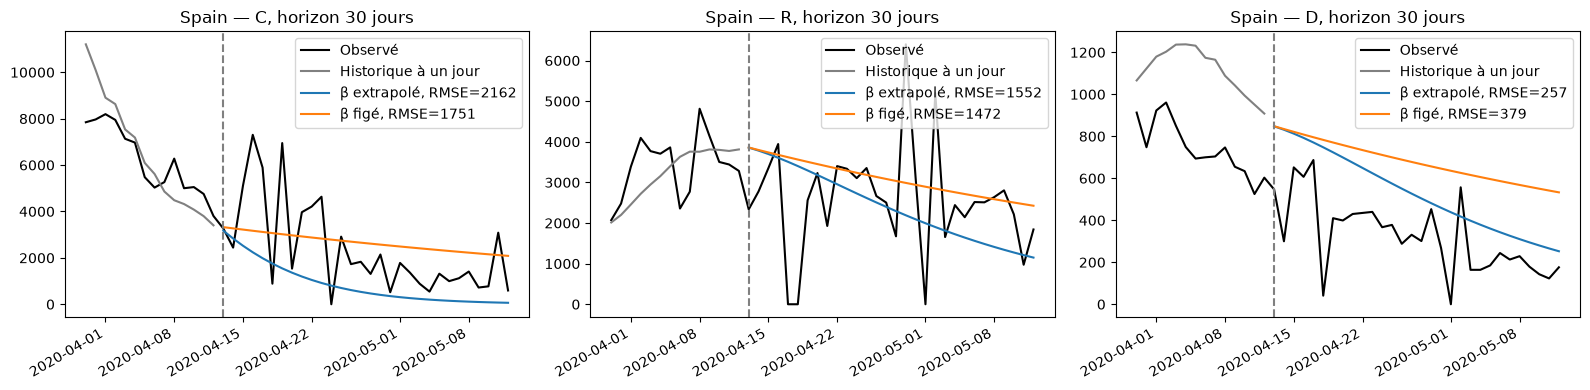

variable,C,D,R
scenario,,,
β extrapolé,2162.388162,256.748925,1551.530520
β figé,1751.327823,379.242860,1472.076738


In [44]:
# Paramètres de la dernière fenêtre observée, conservés sur tout l'horizon.
train_variable = obs_variable.tail(window_variable)
t_end_variable = float((train_variable.index[-1] - train_variable.index[0]).days)
last_parameters_variable = parameters_variable[window_variable].loc[
    obs_variable.index[-1], ["beta_end", "alpha", "f", "k"]
].astype(float)
print("Paramètres de la dernière fenêtre :")
print(last_parameters_variable)

times_future_variable = t_end_variable + np.arange(horizon_variable + 1)
dates_future_variable = pd.date_range(
    obs_variable.index[-1], periods=horizon_variable + 1, freq="D"
)
forecast_cumulative_variable = {}
forecast_daily_variable = {}
for scenario in ["β extrapolé", "β figé"]:
    theta = last_parameters_variable.to_numpy().copy()
    if scenario == "β figé":
        theta[3] = 0.0
    path = integrate_variable(
        theta, obs_variable.iloc[-1].to_numpy(), times_future_variable,
        pop_variable, t_end_variable,
    )
    path = pd.DataFrame(path, index=dates_future_variable, columns=variables_variable)
    forecast_cumulative_variable[scenario] = path.iloc[1:]
    # Inclut le dernier cumul observé pour calculer le premier jour prédit.
    forecast_daily_variable[scenario] = path.diff().iloc[1:]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
rmse_records_variable = []
for ax, variable in zip(axes, variables_variable):
    observed_daily = val_data[variable][country_variable]
    ax.plot(observed_daily.loc[train_variable.index[0]:dates_future_variable[-1]],
            color="black", label="Observé")
    historical = daily_one_step_variable[window_variable][variable].dropna()
    ax.plot(historical.loc[train_variable.index[0]:], color="grey",
            label="Historique à un jour")
    for scenario, forecast in forecast_daily_variable.items():
        pred = forecast[variable]
        truth = observed_daily.reindex(pred.index)
        if truth.isna().any():
            raise ValueError("Données de validation manquantes sur l'horizon demandé")
        rmse = np.sqrt(np.mean((pred - truth)**2))
        rmse_records_variable.append({"scenario": scenario, "variable": variable, "RMSE": rmse})
        ax.plot(pred, label=f"{scenario}, RMSE={rmse:.0f}")
    ax.axvline(dates_future_variable[1], color="grey", linestyle="--")
    ax.set_title(f"{country_variable} — {variable}, horizon {horizon_variable} jours")
    ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()
rmse_variable = pd.DataFrame(rmse_records_variable).pivot(
    index="scenario", columns="variable", values="RMSE"
)
display(rmse_variable)

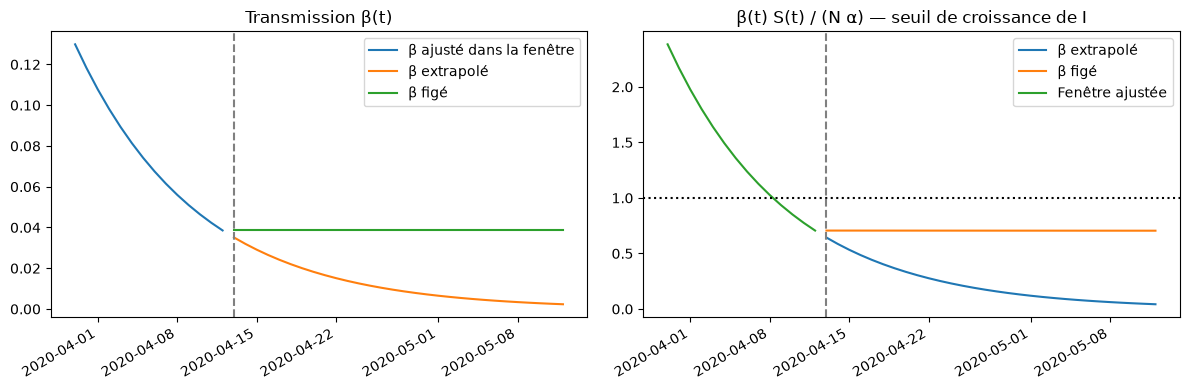

In [45]:
# Diagnostic local : β et croissance du stock infecté sur la dernière fenêtre.
beta_end, alpha, f, k = last_parameters_variable.to_numpy()
times_train_variable = (train_variable.index - train_variable.index[0]).days.to_numpy(dtype=float)
fitted_variable = integrate_variable(
    last_parameters_variable.to_numpy(), train_variable.iloc[0].to_numpy(),
    times_train_variable, pop_variable, t_end_variable,
)
beta_train_variable = beta_end * np.exp(k * (times_train_variable - t_end_variable))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(train_variable.index, beta_train_variable, label="β ajusté dans la fenêtre")
for scenario, forecast in forecast_cumulative_variable.items():
    future_k = k if scenario == "β extrapolé" else 0.0
    beta_future = beta_end * np.exp(future_k * np.arange(1, horizon_variable + 1))
    axes[0].plot(forecast.index, beta_future, label=scenario)
    if alpha > 0:
        axes[1].plot(forecast.index, beta_future * (1 - forecast["C"] / pop_variable) / alpha,
                     label=scenario)
if alpha > 0:
    axes[1].plot(train_variable.index,
                 beta_train_variable * (1 - fitted_variable[:, 0] / pop_variable) / alpha,
                 label="Fenêtre ajustée")
else:
    axes[1].text(0.1, 0.5, "Rapport indéfini : alpha = 0", transform=axes[1].transAxes)
axes[1].axhline(1, color="black", linestyle=":")
axes[0].set_title("Transmission β(t)")
axes[1].set_title("β(t) S(t) / (N α) — seuil de croissance de I")
for ax in axes:
    ax.axvline(dates_future_variable[1], color="grey", linestyle="--")
    ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.show()